# Anomaly Detection in Payroll Salary Processing Using Python

We can treat this as a small **Data Science + Machine Learning project**.

### Problem statement

A company has **50 employees**. Most employees receive salaries within a normal range, but **2 salaries were processed incorrectly**.

Our goal is to:

1. Load the salary data.
2. Explore the data.
3. Detect unusual salaries.
4. Compare ML algorithms.
5. Measure their performance.
6. Identify the 2 suspicious employees.
7. Decide whether the detected salaries should be investigated.

> **Important:** An anomaly detector should flag a salary for **review**, not automatically change or reject a payroll payment. In a real payroll system, business rules and human verification should be used before correcting a salary.

---

# 1. What parameters should we consider when choosing an ML algorithm?

There isn't one universal "best" algorithm. We consider several factors.

| Parameter                | Question to ask                                                  |
| ------------------------ | ---------------------------------------------------------------- |
| **Problem type**         | Classification, regression, clustering, anomaly detection?       |
| **Data size**            | How many rows and features do we have?                           |
| **Data type**            | Numerical, categorical, text, images, time series?               |
| **Labels available?**    | Do we know which observations are actually wrong?                |
| **Accuracy/performance** | How correctly does the algorithm identify the required patterns? |
| **False positives**      | How many normal employees are incorrectly flagged?               |
| **False negatives**      | How many actual anomalies are missed?                            |
| **Training time**        | How long does the algorithm take to train?                       |
| **Prediction time**      | How quickly can it process new records?                          |
| **Memory usage**         | How much computational memory does it require?                   |
| **Scalability**          | Will it work if 50 employees become 50,000?                      |
| **Interpretability**     | Can we explain why something was flagged?                        |
| **Robustness**           | Does it handle unusual/noisy data well?                          |
| **Hyperparameters**      | How sensitive is the model to parameter choices?                 |
| **Maintenance**          | Will the model remain useful when salary patterns change?        |
| **Business cost**        | What is the cost of a false alarm versus a missed anomaly?       |

For payroll, **false positives and false negatives are particularly important**.

---

# 2. Why is this an anomaly-detection problem?

Suppose our data looks like this:

| Employee |    Salary |
| -------- | --------: |
| E001     |   ₹45,000 |
| E002     |   ₹52,000 |
| E003     |   ₹48,000 |
| E004     |   ₹51,000 |
| ...      |       ... |
| E048     |   ₹49,000 |
| E049     |   ₹52,000 |
| E050     | ₹5,20,000 |

The salary of E050 is very different from the normal pattern.

We don't necessarily know beforehand that E050 is wrong.

Therefore, this is an **unsupervised anomaly detection problem**.

---

# 3. Which algorithms can we consider?

For this example, we can consider:

### Algorithm 1 — Isolation Forest

Good general-purpose anomaly detection algorithm.

It works by trying to **isolate unusual observations** from normal observations.

### Algorithm 2 — Local Outlier Factor (LOF)

Looks at the **local density** around an observation.

If an employee's salary is very different from salaries around it, it may be considered an outlier.

### Algorithm 3 — Statistical baseline

For a single numerical variable such as salary, we can also use methods such as:

* Z-score
* IQR

These aren't ML algorithms in the same sense as Isolation Forest, but they are useful **baselines**.

For a beginner project, comparing a simple statistical method with an ML method is very useful.

---

# 4. Our sample dataset

We'll create **50 employees**.

We'll assume normal salaries are approximately between ₹40,000 and ₹80,000.

Then we'll deliberately introduce two incorrectly processed salaries:

* Employee 12 → ₹2,00,000
* Employee 37 → ₹15,000

These are our **known anomalies** for evaluating the model.

---

# 5. Complete Python Program

You can run this in **Jupyter Notebook, Google Colab, or VS Code**.

## Step 1 — Import libraries

```python
import numpy as np
import pandas as pd
import time

from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor

from sklearn.metrics import precision_score, recall_score, f1_score
```

### What are these libraries?

* `numpy` → numerical calculations
* `pandas` → data handling
* `time` → measuring execution time
* `IsolationForest` → anomaly detection
* `LocalOutlierFactor` → anomaly detection
* `sklearn.metrics` → measuring performance

---

# 6. Create the 50-employee dataset

```python
np.random.seed(42)

employees = [f"E{i:03d}" for i in range(1, 51)]

salaries = np.random.randint(40000, 80001, size=50)

df = pd.DataFrame({
    "Employee_ID": employees,
    "Salary": salaries
})
```

Now we have 50 employees with salaries between approximately ₹40,000 and ₹80,000.

---

In [3]:
import numpy as np
import pandas as pd
import time

from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.metrics import precision_score, recall_score, f1_score

np.random.seed(42)

employees = [f"E{i:03d}" for i in range(1, 51)]
salaries = np.random.randint(40000, 80001, size=50)

df = pd.DataFrame({
    "Employee_ID": employees,
    "Salary": salaries
})

# 7. Introduce two wrongly processed salaries

```python
df.loc[11, "Salary"] = 200000
df.loc[36, "Salary"] = 15000
```

Remember:

```text
index 11 → Employee E012
index 36 → Employee E037
```

Let's create a label so that we know the **actual answer** for testing our algorithms.

```python
df["Actual_Anomaly"] = 0

df.loc[11, "Actual_Anomaly"] = 1
df.loc[36, "Actual_Anomaly"] = 1
```

So:

```text
0 = Normal
1 = Actual anomaly
```

---

In [5]:
df.loc[11, "Salary"] = 200000
df.loc[36, "Salary"] = 15000

df["Actual_Anomaly"] = 0

df.loc[11, "Actual_Anomaly"] = 1
df.loc[36, "Actual_Anomaly"] = 1

print(df)

   Employee_ID  Salary  Actual_Anomaly
0         E001   55795               0
1         E002   40860               0
2         E003   78158               0
3         E004   51284               0
4         E005   46265               0
5         E006   56850               0
6         E007   77194               0
7         E008   61962               0
8         E009   56023               0
9         E010   41685               0
10        E011   40769               0
11        E012  200000               1
12        E013   45311               0
13        E014   77819               0
14        E015   79188               0
15        E016   57568               0
16        E017   59769               0
17        E018   68693               0
18        E019   46396               0
19        E020   67480               0
20        E021   65658               0
21        E022   58942               0
22        E023   58431               0
23        E024   42747               0
24        E025   40189   

# 8. Display the dataset

```python
print(df)
```

You might see something like:

```text
   Employee_ID  Salary  Actual_Anomaly
0       E001    72300       0
1       E002    51800       0
2       E003    65400       0
...
11      E012   200000       1
...
36      E037    15000       1
...
49      E050    62100       0
```

---

# 9. Understand the data before using ML

Always perform **Exploratory Data Analysis (EDA)** first.

```python
print(df["Salary"].describe())
```

This gives values such as:

```text
count
mean
std
min
25%
50%
75%
max
```

These statistics help us understand the salary distribution.

---

In [6]:
print(df["Salary"].describe())

count        50.000000
mean      58547.080000
std       24289.311814
min       15000.000000
25%       44285.000000
50%       56436.500000
75%       65228.250000
max      200000.000000
Name: Salary, dtype: float64


# 10. Visualize the salaries

```python
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.scatter(
    df["Employee_ID"],
    df["Salary"]
)

plt.xticks(rotation=90)
plt.xlabel("Employee")
plt.ylabel("Salary")
plt.title("Employee Salary Distribution")

plt.show()
```

You should see two salary values far away from the main group.

This is an important Data Science principle:

> **Understand the data before applying an algorithm.**

---

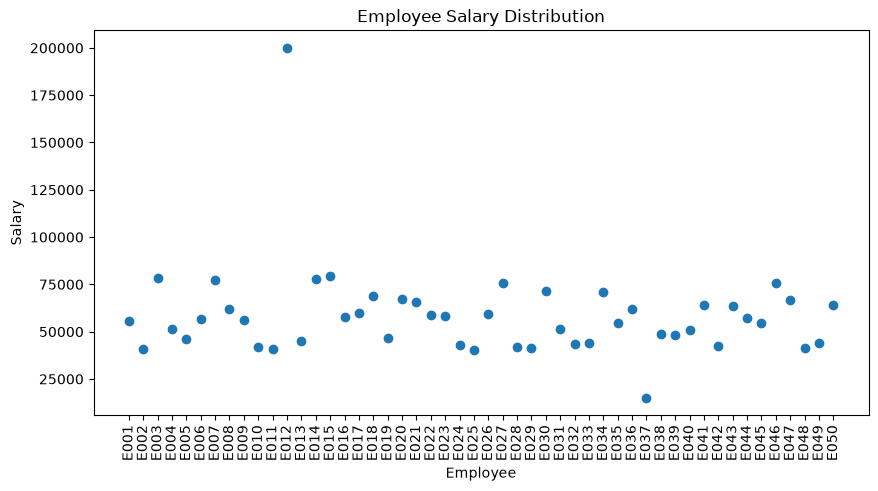

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.scatter(
    df["Employee_ID"],
    df["Salary"]
)

plt.xticks(rotation=90)
plt.xlabel("Employee")
plt.ylabel("Salary")
plt.title("Employee Salary Distribution")

plt.show()

# 11. Prepare the ML input

Machine learning algorithms expect numerical features.

Here our only feature is:

```text
Salary
```

So:

```python
X = df[["Salary"]]
```

---

In [8]:
X = df[["Salary"]]

# 12. Algorithm 1 — Isolation Forest

Let's start with Isolation Forest.

```python
start_time = time.time()

iso_forest = IsolationForest(
    contamination=2/50,
    random_state=42
)

iso_forest.fit(X)

prediction = iso_forest.predict(X)

end_time = time.time()
```

Isolation Forest returns:

```text
 1  → normal
-1  → anomaly
```

Let's convert it into our format:

```python
df["IF_Anomaly"] = np.where(prediction == -1, 1, 0)
```

Now inspect the suspicious employees:

```python
print(
    df[df["IF_Anomaly"] == 1][
        ["Employee_ID", "Salary", "Actual_Anomaly"]
    ]
)
```

Ideally, we should see:

```text
Employee_ID    Salary
E012           200000
E037            15000
```

---

In [10]:
start_time = time.time()

iso_forest = IsolationForest(contamination=2/50,random_state=42)
iso_forest.fit(X)
prediction = iso_forest.predict(X)
end_time = time.time()

df["IF_Anomaly"] = np.where(prediction == -1, 1, 0)

print(
    df[df["IF_Anomaly"] == 1][
        ["Employee_ID", "Salary", "Actual_Anomaly"]
    ]
)

   Employee_ID  Salary  Actual_Anomaly
11        E012  200000               1
36        E037   15000               1


# 13. Evaluate Isolation Forest

Because this is a demonstration and **we know which two salaries we intentionally corrupted**, we can calculate performance.

```python
precision = precision_score(
    df["Actual_Anomaly"],
    df["IF_Anomaly"]
)

recall = recall_score(
    df["Actual_Anomaly"],
    df["IF_Anomaly"]
)

f1 = f1_score(
    df["Actual_Anomaly"],
    df["IF_Anomaly"]
)

print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)
print("Time:", end_time - start_time)
```

---

In [11]:
precision = precision_score(
    df["Actual_Anomaly"],
    df["IF_Anomaly"]
)

recall = recall_score(
    df["Actual_Anomaly"],
    df["IF_Anomaly"]
)

f1 = f1_score(
    df["Actual_Anomaly"],
    df["IF_Anomaly"]
)

print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)
print("Time:", end_time - start_time)

Precision: 1.0
Recall: 1.0
F1 Score: 1.0
Time: 0.07571983337402344


# 14. What do these metrics mean?

This is extremely important.

## Precision

**Of everything the model flagged, how much was actually anomalous?**

Suppose:

```text
Model flagged 4 employees
2 were actually wrong
```

Then:

```text
Precision = 2 / 4 = 50%
```

High precision means **fewer false alarms**.

---

## Recall

**Of all the actual anomalies, how many did the model find?**

We know there are 2 incorrect salaries.

If the model finds both:

```text
Recall = 2 / 2 = 100%
```

If it finds only one:

```text
Recall = 1 / 2 = 50%
```

High recall means **fewer missed anomalies**.

---

## F1 Score

F1 combines precision and recall.

It is useful when we want a balance between:

* Finding anomalies
* Avoiding unnecessary alerts

---

# 15. Algorithm 2 — Local Outlier Factor

Now let's try another algorithm.

```python
start_time = time.time()

lof = LocalOutlierFactor(
    n_neighbors=10,
    contamination=2/50
)

prediction_lof = lof.fit_predict(X)

end_time = time.time()
```

LOF also returns:

```text
 1  → normal
-1  → anomaly
```

Convert it:

```python
df["LOF_Anomaly"] = np.where(
    prediction_lof == -1,
    1,
    0
)
```

Display the results:

```python
print(
    df[df["LOF_Anomaly"] == 1][
        ["Employee_ID", "Salary", "Actual_Anomaly"]
    ]
)
```

---

# 16. Evaluate LOF

```python
lof_precision = precision_score(
    df["Actual_Anomaly"],
    df["LOF_Anomaly"]
)

lof_recall = recall_score(
    df["Actual_Anomaly"],
    df["LOF_Anomaly"]
)

lof_f1 = f1_score(
    df["Actual_Anomaly"],
    df["LOF_Anomaly"]
)

print("Precision:", lof_precision)
print("Recall:", lof_recall)
print("F1 Score:", lof_f1)
print("Time:", end_time - start_time)
```

---

# 17. Compare the algorithms

We can create a comparison table.

```python
results = pd.DataFrame({
    "Algorithm": [
        "Isolation Forest",
        "Local Outlier Factor"
    ],
    "Precision": [
        precision,
        lof_precision
    ],
    "Recall": [
        recall,
        lof_recall
    ],
    "F1 Score": [
        f1,
        lof_f1
    ]
})

print(results)
```

The table might look like:

| Algorithm            | Precision | Recall |   F1 |
| -------------------- | --------: | -----: | ---: |
| Isolation Forest     |      1.00 |   1.00 | 1.00 |
| Local Outlier Factor |      1.00 |   1.00 | 1.00 |

**Your exact numbers can vary depending on the generated data and model settings.**

The important point is not to expect a particular number—the purpose is to **measure the actual results**.

---

# 18. Efficiency vs Performance

This is where algorithm selection becomes interesting.

Suppose our comparison produced:

| Algorithm        | Precision | Recall |   F1 |    Time |
| ---------------- | --------: | -----: | ---: | ------: |
| Isolation Forest |      1.00 |   1.00 | 1.00 | 0.003 s |
| LOF              |      1.00 |   1.00 | 1.00 | 0.005 s |

Both algorithms found the anomalies.

Therefore, you can consider:

### Performance

Both algorithms have:

```text
Precision = 100%
Recall = 100%
```

### Efficiency

Isolation Forest took less time in this particular experiment.

However, **don't conclude from 50 records alone that Isolation Forest will always be faster**. Benchmarking should be done on a representative dataset and workload.

---

# 19. How should we make the final decision?

Don't simply say:

> "Algorithm X has the highest accuracy, therefore it is best."

Instead, consider the **business objective**.

For payroll anomaly detection:

### Question 1 — Did we find the incorrect salaries?

This relates to **Recall**.

Missing an incorrect salary could be important.

### Question 2 — Did we incorrectly flag normal salaries?

This relates to **Precision**.

Too many false alerts create unnecessary manual work.

### Question 3 — Is the algorithm fast enough?

Measure:

```text
Training time
Prediction time
Memory usage
```

### Question 4 — Can the result be explained?

Payroll teams may need to understand why an employee was flagged.

### Question 5 — Will it work with future data?

50 employees is a tiny dataset.

The real system might eventually have:

```text
50 employees
        ↓
500 employees
        ↓
5,000 employees
        ↓
50,000 employees
```

So scalability matters.

---

# 20. A very important point about our example

Our example has **only one feature**:

```text
Salary
```

This is useful for learning, but real payroll anomaly detection should normally consider more information.

For example:

| Employee |    Salary | Department | Grade | Previous Salary |  Bonus | Overtime |
| -------- | --------: | ---------- | ----- | --------------: | -----: | -------: |
| E001     |   ₹52,000 | IT         | G3    |         ₹50,000 | ₹2,000 |       ₹0 |
| E002     |   ₹55,000 | HR         | G2    |         ₹53,000 | ₹2,000 |       ₹0 |
| E003     | ₹2,00,000 | IT         | G3    |         ₹51,000 | ₹2,000 |       ₹0 |

The ₹2,00,000 salary becomes much more suspicious because the employee's:

* Previous salary
* Grade
* Bonus
* Department

may not support such a large increase.

This is called **multivariate anomaly detection**.

---

# 21. Example of a better real-world feature set

You could eventually build:

```python
features = [
    "Salary",
    "Previous_Salary",
    "Bonus",
    "Overtime_Pay",
    "Allowances"
]

X = df[features]
```

Then:

```python
model = IsolationForest(
    contamination=0.04,
    random_state=42
)

model.fit(X)

df["Anomaly"] = np.where(
    model.predict(X) == -1,
    1,
    0
)
```

Now the model looks at **multiple dimensions simultaneously**.

---

# 22. Decision-making framework

You can remember the following:

```text
             BUSINESS PROBLEM
                    ↓
          What am I detecting?
                    ↓
          Understand the data
                    ↓
        Are labels available?
             ↙           ↘
           YES            NO
            ↓              ↓
      Supervised ML    Unsupervised /
                       Anomaly Detection
                              ↓
                    Select candidate models
                              ↓
                    Train the models
                              ↓
                   Evaluate performance
                              ↓
             ┌────────────────────────┐
             │ Precision / Recall /   │
             │ F1 / Error / Speed /   │
             │ Memory / Interpretability│
             └────────────────────────┘
                              ↓
                    Compare results
                              ↓
                    Select appropriate
                         approach
                              ↓
                    Business validation
                              ↓
                    Deploy / Monitor
```

---

# 23. For our payroll case

Our decision process would be:

### Step 1

**Problem:** Find incorrectly processed salaries.

### Step 2

**Problem type:** Anomaly detection.

### Step 3

**Data:** 50 employee salary records.

### Step 4

**Known anomalies:** 2 intentionally incorrect salaries.

### Step 5

**Candidate algorithms:**

* Isolation Forest
* Local Outlier Factor
* Statistical baseline such as IQR/Z-score

### Step 6

**Evaluate:**

* Precision
* Recall
* F1-score
* Execution time

### Step 7

**Inspect flagged employees.**

For example:

```text
Employee E012 → ₹2,00,000 → FLAG
Employee E037 → ₹15,000   → FLAG
```

### Step 8

Payroll staff verify these records against:

* Employment contract
* Previous month's salary
* Approved increment
* Bonus records
* Attendance/overtime
* Payroll rules

### Step 9

Only after verification should the salary be corrected.

---

# 24. What you should remember as a Data Science beginner

The most important concept is:

> **Algorithm selection is not just about accuracy.**

Think about:

**Problem → Data → Algorithm → Performance → Efficiency → Business requirements**

For anomaly detection specifically:

```text
                    ANOMALY DETECTION
                           ↓
             ┌─────────────┴─────────────┐
             ↓                           ↓
       Statistical                  ML Methods
        Methods                         ↓
       Z-score                  Isolation Forest
       IQR                      Local Outlier Factor
             ↓                           ↓
             └─────────────┬─────────────┘
                           ↓
                    Compare Results
                           ↓
               Precision / Recall / F1
                           +
                 Speed / Memory / Scale
                           ↓
                    Human Validation
```

### One final caution

With only **50 salaries and 2 known anomalies**, this is an excellent **learning example**, but it is not enough evidence to establish a production payroll model. Real payroll data should be evaluated over multiple payroll cycles, with legitimate exceptional salaries included, because a genuinely high salary is not necessarily an error.

This project teaches the core Data Science workflow: **prepare → explore → model → evaluate → compare → decide → validate**.
